# Clasificación de Marcha Sagital: Niños Control vs. Parálisis Cerebral

Clasificación binaria entre **marcha típica (control)** y **marcha con parálisis cerebral (case)** a partir de los ciclos cinemáticos sagitales normalizados (`gait_cycles_normalized_sagittal.parquet`) en `derivatives/`.

### Pipeline
1. **Entrada:** ciclos normalizados a 101 puntos (0–100 % del ciclo) de cadera, rodilla y tobillo, izquierda y derecha (6 señales por ciclo).
2. **Evaluación:** validación cruzada **repetida y agrupada por sujeto** (4 folds × 5 repeticiones, estratificada por clase). Con ~56 sujetos, un único split train/val/test deja 3 casos en test y sus métricas no son concluyentes.
3. **Modelos:**
   - **Random Forest** sobre 36 biomarcadores por ciclo (media, DE, mín., máx., ROM y asimetría).
   - **GaitCNN1D** sobre las curvas completas (6 × 101), con early stopping sobre un split interno de sujetos de train.
4. **Métrica principal:** **AUC a nivel paciente** (promedio de las probabilidades de los ciclos de cada niño), con IC95 % por bootstrap de sujetos. Sensibilidad, especificidad y exactitud balanceada se reportan aparte, a umbral fijo 0.5 **sin calibrar**.
5. **Ponderación:** cada ciclo pesa `1 / n_ciclos_del_sujeto` y las clases se balancean a nivel sujeto, de modo que ningún niño pesa más por tener más ciclos.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from src.sagittal import (
    load_sagittal_dataset,
    fit_predict_rf,
    fit_predict_cnn,
    cross_validate_subjects,
    summarize_cv,
    cv_permutation_importance,
    SIGNALS,
)

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

COLORS = {'control': '#1b9e77', 'case': '#d95f02'}

## 1. Carga del Dataset e Inventario de Sujetos y Ciclos

Cargamos los archivos `gait_cycles_normalized_sagittal.parquet` de `derivatives/` y vinculamos cada sujeto con su grupo (`case` / `control`) mediante `subject_split.csv`.

> **Limitación de cobertura:** `subject_split.csv` lista 68 sujetos (27 casos), pero solo 56 (17 casos) tienen ciclos normalizados bilaterales. El resto queda fuera del análisis (el loader lo advierte); el origen de esa omisión está en el procesamiento previo de `derivatives/` y no se corrige aquí. Esto reduce el número de casos, que es el factor que más limita la potencia estadística.

In [2]:
DERIVATIVES_DIR = '../derivatives'
SPLIT_CSV = '../derivatives/time_series_prediction/subject_split.csv'

df_cycles, X_curves, X_tabular, y, subjects, feature_names = load_sagittal_dataset(
    derivatives_dir=DERIVATIVES_DIR,
    split_csv_path=SPLIT_CSV
)

print('=== RESUMEN DEL DATASET CARGADO ===')
print(f'Total ciclos bilaterales completos: {len(df_cycles)}')
print(f'Forma tensor de curvas continuas (N, canales, puntos): {X_curves.shape}')
print(f'Forma matriz de caracteristicas tabulares (N, features): {X_tabular.shape}')
print(f'Numero total de sujetos unicos: {df_cycles["subject_id"].nunique()}')
print(f'Numero total de trials: {df_cycles.groupby(["subject_id", "trial_label"]).ngroups}')

print('\nDistribucion por Grupo Clinico:')
for grp, count in df_cycles.groupby('group')['subject_id'].nunique().items():
    n_c = (df_cycles['group'] == grp).sum()
    n_t = df_cycles[df_cycles['group'] == grp].groupby(['subject_id', 'trial_label']).ngroups
    print(f'  - Grupo {grp.upper():<7}: {count:>2} sujetos | {n_t:>2} trials | {n_c:>3} ciclos ({n_c/len(df_cycles)*100:.1f}%) | {n_c/count:.1f} ciclos/sujeto')

df_cycles.head(6)

=== RESUMEN DEL DATASET CARGADO ===
Total ciclos bilaterales completos: 212
Forma tensor de curvas continuas (N, canales, puntos): (212, 6, 101)
Forma matriz de caracteristicas tabulares (N, features): (212, 36)
Numero total de sujetos unicos: 56
Numero total de trials: 57

Distribucion por Grupo Clinico:
  - Grupo CASE   : 17 sujetos | 17 trials |  52 ciclos (24.5%) | 3.1 ciclos/sujeto
  - Grupo CONTROL: 39 sujetos | 40 trials | 160 ciclos (75.5%) | 4.1 ciclos/sujeto


/mnt/c/Users/USER/Downloads/Proyecto de Investigacion EXOESQUELETO/cp-sagittal-gait-classification/notebooks/../src/sagittal.py:175: UserWarning: 12 de 68 sujetos del CSV no tienen ciclos normalizados bilaterales y quedan fuera: ['subject_0002', 'subject_0003', 'subject_0004', 'subject_0005', 'subject_0007', 'subject_0008', 'subject_0009', 'subject_0011', 'subject_0030', 'subject_0033', 'subject_0063', 'subject_0067']
  warnings.warn(


,subject_id,trial_label,cycle_id,group,label,is_best,source_file
0,subject_0001,trial_01,0,case,1,True,../derivatives/subject_0001/session_01/pose/tr...
1,subject_0001,trial_01,1,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
2,subject_0001,trial_01,2,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
3,subject_0001,trial_01,3,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
4,subject_0010,trial_01,0,case,1,True,../derivatives/subject_0010/session_01/pose/tr...
5,subject_0010,trial_01,1,case,1,False,../derivatives/subject_0010/session_01/pose/tr...


## 2. Análisis Exploratorio: Curvas Cinemáticas Sagitales Promedio

Se promedian primero los ciclos de cada sujeto y luego se calcula la media y la desviación estándar **entre sujetos**. Así la banda refleja variabilidad inter-sujeto y los niños con más ciclos no dominan la curva. Eje x: 0 % (contacto inicial) a 100 % (siguiente contacto del mismo pie).

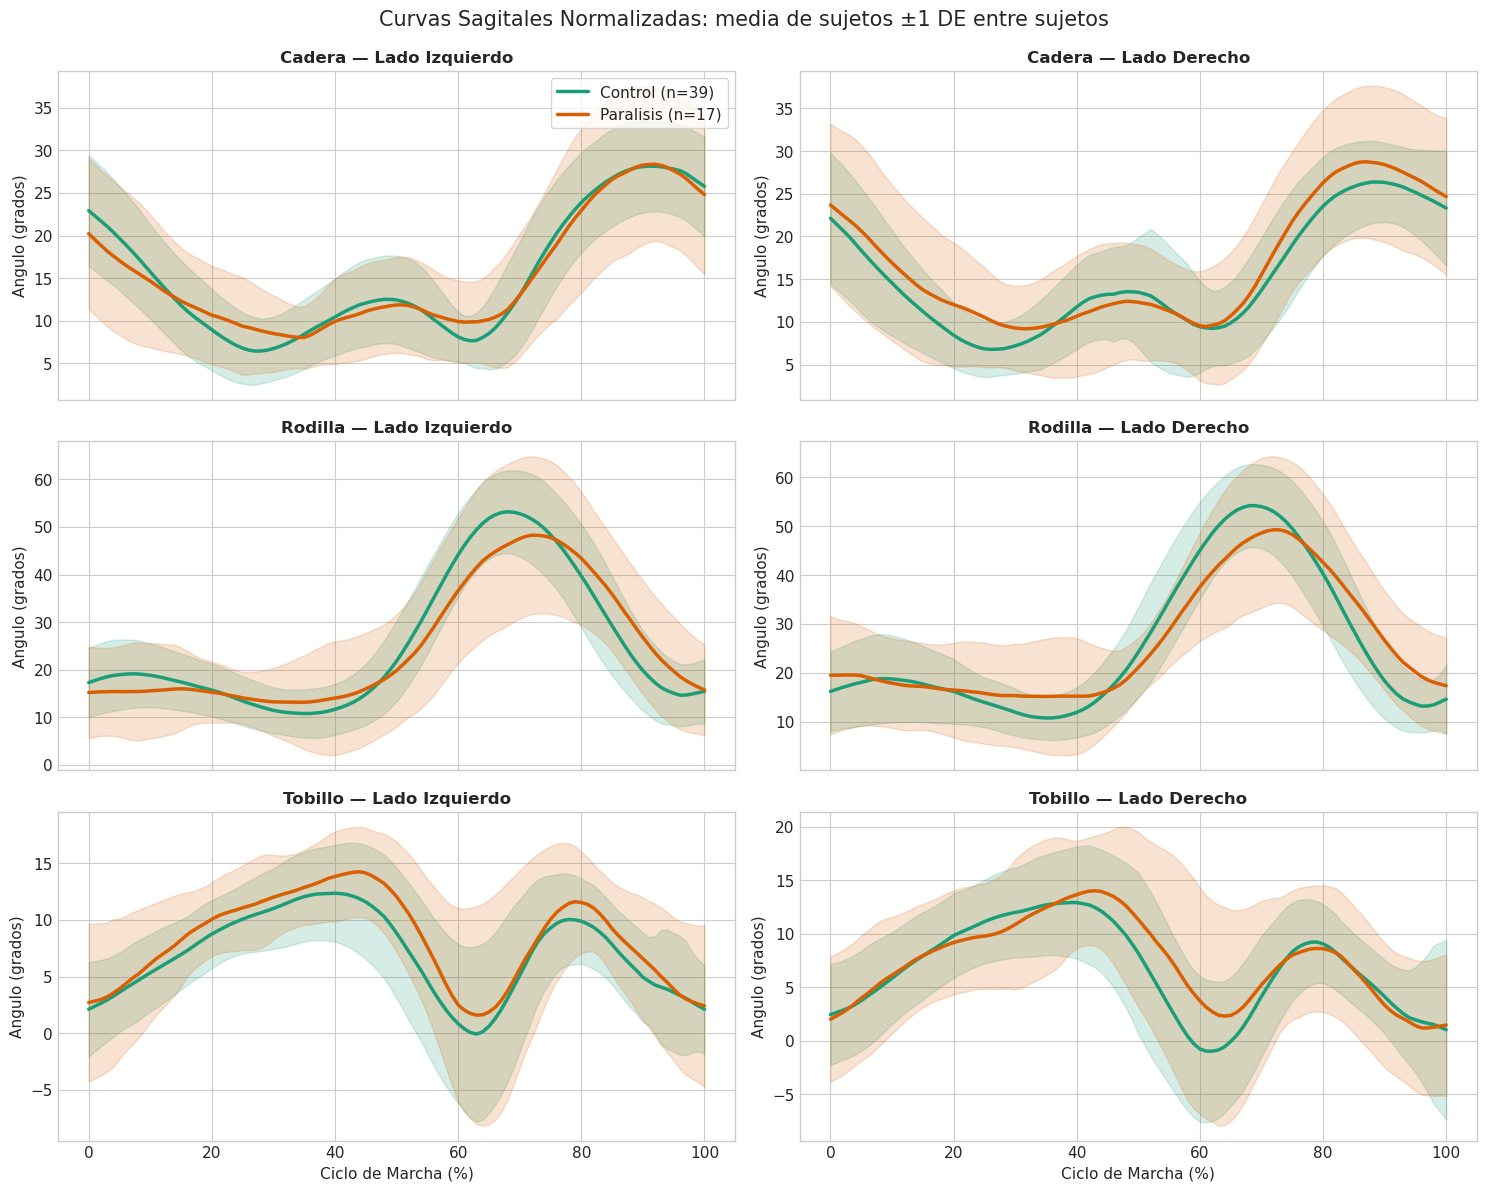

In [3]:
pct = np.linspace(0, 100, 101)

# Media por sujeto: (n_sujetos, 6, 101)
uniq_subjects = pd.unique(subjects)
S_curves = np.stack([X_curves[subjects == s].mean(axis=0) for s in uniq_subjects])
S_y = np.array([y[subjects == s][0] for s in uniq_subjects])

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)

joints = [('hip', 'Cadera'),
          ('knee', 'Rodilla'),
          ('ankle', 'Tobillo')]
sides = [('left', 'Lado Izquierdo'), ('right', 'Lado Derecho')]

for r, (joint, joint_title) in enumerate(joints):
    for c, (side, side_title) in enumerate(sides):
        ax = axes[r, c]
        sig_idx = SIGNALS.index((side, joint))

        for grp, label_val, name in [('control', 0, 'Control'), ('case', 1, 'Paralisis')]:
            vals = S_curves[S_y == label_val, sig_idx, :]
            mean, std = vals.mean(axis=0), vals.std(axis=0)
            n = vals.shape[0]
            ax.plot(pct, mean, color=COLORS[grp], lw=2.5, label=f'{name} (n={n})')
            ax.fill_between(pct, mean - std, mean + std, color=COLORS[grp], alpha=0.18)

        ax.set_title(f'{joint_title} — {side_title}', fontweight='bold')
        ax.set_ylabel('Angulo (grados)')
        if r == 2:
            ax.set_xlabel('Ciclo de Marcha (%)')
        if r == 0 and c == 0:
            ax.legend(loc='upper right', frameon=True)

plt.suptitle('Curvas Sagitales Normalizadas: media de sujetos ±1 DE entre sujetos', fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

### Lectura y límites de las curvas

Las bandas se solapan en buena parte del ciclo, lo que anticipa una separación imperfecta entre grupos. **No se interpretan aquí patrones clínicos específicos** (marcha en equino, *crouch*, *stiff knee*, hiperextensión), por dos razones:

1. Los ángulos provienen de **estimación de pose por video** (`pose/`), considerablemente más ruidosa que la captura con marcadores.
2. En cadera y rodilla ningún grupo toma valores negativos (mínimo ≈ 0°), lo que sugiere **ángulos sin signo** que no distinguen flexión de extensión. Esto debe verificarse en el procesamiento previo antes de leer las curvas como flexión/extensión.

## 3. Biomarcadores por Sujeto

Descriptores usados por el Random Forest, aquí promediados por sujeto (un punto por niño):
- **ROM:** $\text{ROM} = \max(\theta) - \min(\theta)$ por articulación.
- **Asimetría:** diferencia absoluta de ROM entre lados. Se calcula entre ciclos izquierdo y derecho con el mismo `cycle_id`, que **no son el mismo paso** (sus inicios difieren en torno a medio ciclo), por lo que mide asimetría entre zancadas consecutivas.

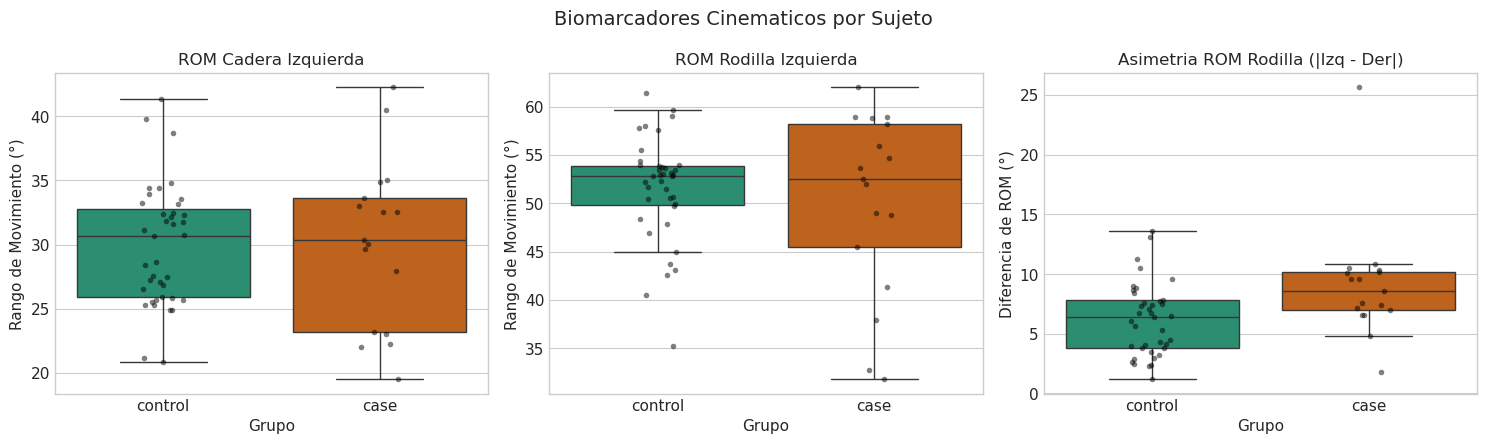

In [4]:
df_features = pd.DataFrame(X_tabular, columns=feature_names)
df_features['subject'] = subjects
df_features['group'] = df_cycles['group'].values
df_subj = df_features.groupby(['subject', 'group'], as_index=False).mean(numeric_only=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    ('left_hip_rom', 'ROM Cadera Izquierda', 'Rango de Movimiento (°)'),
    ('left_knee_rom', 'ROM Rodilla Izquierda', 'Rango de Movimiento (°)'),
    ('asymmetry_rom_knee', 'Asimetria ROM Rodilla (|Izq - Der|)', 'Diferencia de ROM (°)'),
]
for ax, (col, title, ylabel) in zip(axes, panels):
    sns.boxplot(x='group', y=col, hue='group', data=df_subj, order=['control', 'case'],
                palette=COLORS, legend=False, fliersize=0, ax=ax)
    sns.stripplot(x='group', y=col, data=df_subj, order=['control', 'case'],
                  color='black', alpha=0.5, size=4, ax=ax)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Grupo')

plt.suptitle('Biomarcadores Cinematicos por Sujeto', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Validación Cruzada Repetida Agrupada por Sujeto

Cada repetición reparte los sujetos en 4 folds estratificados por clase; cada niño cae una vez en test y **todos sus ciclos quedan en el mismo lado de la partición** (hay un `assert` de no solapamiento). Se repite 5 veces con particiones distintas.

- **Random Forest:** `class_weight` se sustituye por pesos por sujeto y clase (`sample_weights`).
- **GaitCNN1D:** las curvas se normalizan por canal con estadísticos del train; el entrenamiento se detiene (*early stopping*) según la pérdida en un split interno de sujetos de train, de modo que **el test nunca interviene en el ajuste**.
- La probabilidad de cada niño es el promedio de las de sus ciclos de test.

In [5]:
N_SPLITS, N_REPEATS, SEED = 4, 5, 42

models = {
    'Random Forest (36 features)': (fit_predict_rf, X_tabular),
    'GaitCNN1D (curvas)': (fit_predict_cnn, X_curves),
}

oof = cross_validate_subjects(models, y, subjects, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED)
summary, p_avg = summarize_cv(oof, y, subjects, threshold=0.5)

y_subj = pd.Series(y, index=subjects).groupby(level=0).first()
print(f'Sujetos evaluados: {len(y_subj)} (case={int(y_subj.sum())}, control={int((1 - y_subj).sum())})')
print(f'CV: {N_SPLITS} folds x {N_REPEATS} repeticiones = {N_SPLITS * N_REPEATS} ajustes por modelo')

Sujetos evaluados: 56 (case=17, control=39)
CV: 4 folds x 5 repeticiones = 20 ajustes por modelo


## 5. Resultados: AUC a Nivel Paciente (métrica principal)

El AUC mide si el modelo **ordena** a los casos por encima de los controles y no depende del umbral. El azar es 0.5.

- *Media ± DE:* entre las 5 repeticiones (variabilidad por la partición).
- *IC95 %:* bootstrap de sujetos sobre la probabilidad promediada entre repeticiones. Es algo optimista (el promedio reduce varianza) y queda centrado por encima de la media por repetición; conviene leerlo como orientativo.
- *Gráfico:* las curvas finas son una por repetición; la gruesa usa la probabilidad promediada entre repeticiones, por eso se ve algo mejor que el AUC por repetición de la leyenda.

,Modelo,AUC (media ± DE entre repeticiones),IC95% bootstrap de sujetos
0,Random Forest (36 features),0.790 ± 0.035,"[0.68, 0.93]"
1,GaitCNN1D (curvas),0.649 ± 0.033,"[0.61, 0.88]"


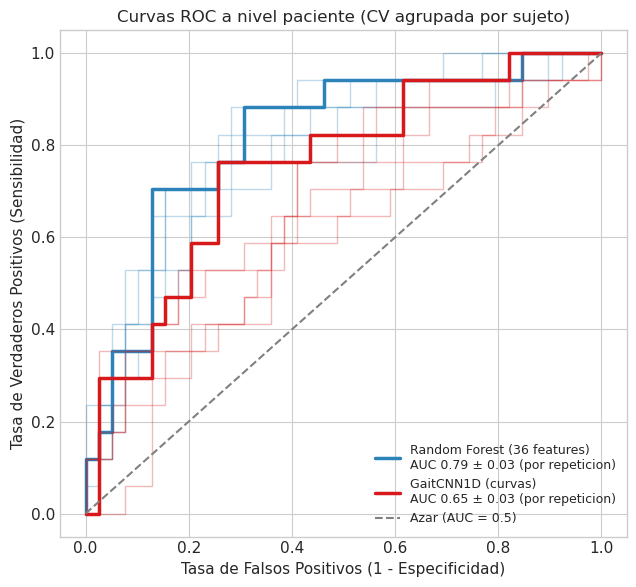

In [6]:
table_auc = pd.DataFrame({
    'Modelo': summary['modelo'],
    'AUC (media ± DE entre repeticiones)': [f'{m:.3f} ± {s:.3f}' for m, s in zip(summary['auc_mean'], summary['auc_sd'])],
    'IC95% bootstrap de sujetos': [f'[{lo:.2f}, {hi:.2f}]' for lo, hi in zip(summary['auc_ci_lo'], summary['auc_ci_hi'])],
})
display(table_auc)

fig, ax = plt.subplots(figsize=(6.5, 6))
palette = ['#2b83ba', '#d7191c']
for color, (_, row) in zip(palette, summary.iterrows()):
    name = row['modelo']
    # Finas: una curva por repeticion de la CV. Gruesa: probabilidad promediada entre repeticiones.
    for rep in oof[name]:
        ids = list(rep)
        fpr, tpr, _ = roc_curve(y_subj.loc[ids].values, [rep[i] for i in ids])
        ax.plot(fpr, tpr, color=color, lw=1, alpha=0.3)
    p = p_avg[name]
    fpr, tpr, _ = roc_curve(y_subj.loc[p.index].values, p.values)
    ax.plot(fpr, tpr, color=color, lw=2.5, label=f"{name}\nAUC {row['auc_mean']:.2f} ± {row['auc_sd']:.2f} (por repeticion)")
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Azar (AUC = 0.5)')
ax.set_title('Curvas ROC a nivel paciente (CV agrupada por sujeto)')
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

## 6. Métricas a Umbral Fijo 0.5 (sin calibrar)

> **Secundaria. No usar para comparar modelos.** Estas métricas dependen del corte y de cómo cada modelo calibra sus probabilidades. La CNN, entrenada con pérdida ponderada, queda más cerca de un corte balanceado que el Random Forest, cuyas probabilidades se comprimen hacia la clase mayoritaria. Un RF con AUC alto puede tener sensibilidad casi nula a 0.5 sin que eso refleje su capacidad de ordenar. El umbral **no se calibró** (con pocos casos sería inestable); la referencia es el AUC.

In [7]:
table_thr = pd.DataFrame({
    'Modelo': summary['modelo'],
    'Exactitud balanceada': summary['bal_acc'].map('{:.3f}'.format),
    'Sensibilidad': summary['sens'].map('{:.3f}'.format),
    'Especificidad': summary['spec'].map('{:.3f}'.format),
})
print('Umbral fijo 0.5, sin calibrar (media entre repeticiones, nivel paciente):')
display(table_thr)

Umbral fijo 0.5, sin calibrar (media entre repeticiones, nivel paciente):


,Modelo,Exactitud balanceada,Sensibilidad,Especificidad
0,Random Forest (36 features),0.509,0.024,0.995
1,GaitCNN1D (curvas),0.603,0.529,0.677


## 7. Importancia de Características (Random Forest)

Importancia por **permutación**: caída del AUC por ciclo al permutar cada característica en los folds de **test**, promediada entre folds. Es más estable que la importancia Gini cuando las características están correlacionadas (aquí lo están: media, mín., máx. y ROM de una misma señal) y no se mide sobre datos vistos en el entrenamiento. Con tan pocos sujetos sigue siendo una guía exploratoria.

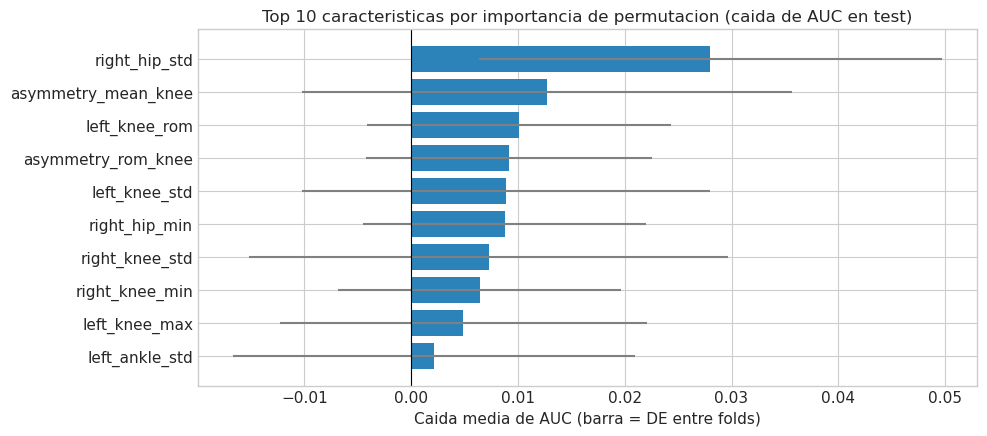

,feature,auc_drop_mean,auc_drop_sd
0,right_hip_std,0.028003,0.021667
1,asymmetry_mean_knee,0.012716,0.022917
2,left_knee_rom,0.010106,0.014269
3,asymmetry_rom_knee,0.009121,0.013395
4,left_knee_std,0.008881,0.019096
5,right_hip_min,0.008766,0.013245
6,right_knee_std,0.007266,0.022413
7,right_knee_min,0.006402,0.013253
8,left_knee_max,0.004884,0.017214
9,left_ankle_std,0.002137,0.018787


In [8]:
imp = cv_permutation_importance(
    X_tabular, y, subjects, feature_names, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED
)

top = imp.head(10).iloc[::-1]
plt.figure(figsize=(10, 4.5))
plt.barh(top['feature'], top['auc_drop_mean'], xerr=top['auc_drop_sd'], color='#2b83ba', ecolor='gray')
plt.axvline(0, color='black', lw=0.8)
plt.title('Top 10 caracteristicas por importancia de permutacion (caida de AUC en test)')
plt.xlabel('Caida media de AUC (barra = DE entre folds)')
plt.tight_layout()
plt.show()

imp.head(10)

## 8. Conclusiones

1. **Cobertura.** Se evaluaron 56 sujetos (17 casos, 39 controles; 212 ciclos). Otros 12 sujetos del CSV (10 casos) no tienen ciclos normalizados y quedan fuera. Con 17 casos, toda estimación es inestable.

2. **Señal discriminativa moderada, no alta.** El Random Forest alcanza un AUC a nivel paciente de 0.79 ± 0.04 entre repeticiones (IC95 % [0.68, 0.93]), claramente por encima del azar. La CNN queda en 0.65 ± 0.03, con un IC orientativo [0.61, 0.88] que es optimista por construcción. Esto indica que hay información discriminativa en las curvas sagitales, pero no justifica hablar de "alta capacidad" de clasificación.

3. **Deep learning no aporta aquí.** La CNN no supera al Random Forest sobre biomarcadores (los IC se solapan, pero el AUC por repetición es menor). Con 56 sujetos no hay base para preferir el modelo más complejo.

4. **Umbral 0.5 sin calibrar.** A ese corte el Random Forest casi no detecta casos (sensibilidad ≈ 0.02, especificidad ≈ 0.99) mientras que la CNN reparte mejor los errores (≈ 0.53 / 0.68). Eso refleja la calibración de cada modelo y no su capacidad de ordenar; no debe usarse para compararlos ni como desempeño clínico.

5. **Importancia de características no concluyente.** Ninguna característica destaca: la mayor caída de AUC por permutación es ≈ 0.03 (`right_hip_std`) y en la mayoría la desviación entre folds es igual o mayor que la media. No se puede afirmar qué biomarcadores son determinantes. La versión anterior del notebook atribuía ese rol al ROM de rodilla y tobillo y a la asimetría; con esta evaluación esa afirmación no se sostiene.

### Limitaciones
- Pocos casos y un solo trial por sujeto; sin validación externa. Todos los registros son de la misma cámara y sesión.
- Datos de estimación de pose por video, más ruidosos que la captura con marcadores.
- Cadera y rodilla parecen ángulos sin signo (sin valores negativos en ningún grupo), lo que impide interpretarlos como flexión/extensión hasta verificarlo en el procesamiento previo.
- La asimetría compara zancadas consecutivas (ciclos izquierdo y derecho con el mismo `cycle_id`), no pasos simultáneos.
- El IC por bootstrap sobre probabilidades promediadas es optimista.

**En resumen:** hay señal exploratoria que justifica seguir con más sujetos (en particular recuperar los 10 casos excluidos), pero estos resultados no permiten afirmar un desempeño diagnóstico.